# Reward Hacking in Language-Model Alignment — Option 3
Author: [Your name] | Register number: [Your register number] | Date: [Submission date]

## Research question
Can optimization against a misspecified proxy reward increase the proxy score while reducing quality under a separately defined gold reward?

**Scope:** This is a synthetic, transparent simulation using a finite set of weather reports. It does not fine-tune a pretrained language model or use human preference data.

Run all cells using **Runtime → Run all** in Google Colab. Verify outputs before submitting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MASTER_SEED = 42
conditions = [("sunny skies",22),("light rain",19),("cloudy skies",18),
              ("windy weather",16),("clear skies",24),("heavy rain",17),
              ("mild weather",21),("cool conditions",15)]
fillers = ["", "excellent", "excellent excellent",
           "excellent excellent excellent",
           "excellent excellent excellent excellent",
           "excellent excellent excellent excellent excellent"]
rows=[]
for condition,temp in conditions:
    for filler in fillers:
        text=f"Forecast: {condition}, {temp} degrees. {filler}".strip()
        fc=filler.split().count("excellent")
        wc=len(text.replace(".","").replace(",","").split())
        rows.append({"text":text,"temperature_present":1,"filler_count":fc,
                     "word_count":wc,"condition":condition,"temperature":temp})
candidates=pd.DataFrame(rows)

def gold_reward(r):
    return 1.0*r["temperature_present"] - 0.25*r["filler_count"] - 0.03*r["word_count"]
def proxy_reward(r):
    return 1.0*r["temperature_present"] + 0.35*r["filler_count"] - 0.02*r["word_count"]
candidates["gold_reward"]=candidates.apply(gold_reward,axis=1)
candidates["proxy_reward"]=candidates.apply(proxy_reward,axis=1)

def judge(r):
    return int(r["temperature_present"] == 1 and r["filler_count"] < 2)

def run_search(budget, seed, trials=250):
    rng=np.random.default_rng(seed)
    out=[]
    for _ in range(trials):
        ix=rng.choice(len(candidates),size=min(budget,len(candidates)),replace=False)
        subset=candidates.iloc[ix]
        chosen=subset.loc[subset["proxy_reward"].idxmax()]
        out.append({"proxy_reward":chosen["proxy_reward"],
                    "gold_reward":chosen["gold_reward"],
                    "word_count":chosen["word_count"],
                    "filler_count":chosen["filler_count"],
                    "judge_pass":judge(chosen)})
    return pd.DataFrame(out)

budgets=[1,2,4,8,16,32]
primary=[]
for b in budgets:
    r=run_search(b,MASTER_SEED+b)
    primary.append({"search_budget":b,"mean_proxy_reward":r.proxy_reward.mean(),
                    "mean_gold_reward":r.gold_reward.mean(),"mean_word_count":r.word_count.mean(),
                    "judge_pass_rate":r.judge_pass.mean(),"mean_filler_count":r.filler_count.mean()})
primary=pd.DataFrame(primary)
print("Candidate pool size:",len(candidates))
display(primary.round(3))

Candidate pool size: 48


,search_budget,mean_proxy_reward,mean_gold_reward,mean_word_count,judge_pass_rate,mean_filler_count
0,1,1.666,0.200,7.320,0.364,2.320
1,2,2.062,-0.136,8.520,0.104,3.520
2,4,2.363,-0.391,9.432,0.004,4.432
3,8,2.473,-0.485,9.768,0.000,4.768
4,16,2.541,-0.542,9.972,0.000,4.972
5,32,2.550,-0.550,10.000,0.000,5.000


## 1. Reward definitions and decision process
The **proxy reward** rewards the repeated word “excellent,” even though repetition does not add useful weather information. The **gold reward** rewards a numeric temperature and penalizes filler and verbosity. For each trial, the optimizer samples a subset of candidates and chooses the report with the highest proxy score. The search budget is the number of candidates considered.

## 2. Proxy versus gold reward
The independent rule-based judge passes a report if it contains a numeric temperature and fewer than two “excellent” tokens. It is separate from the proxy formula but is only a narrow check.

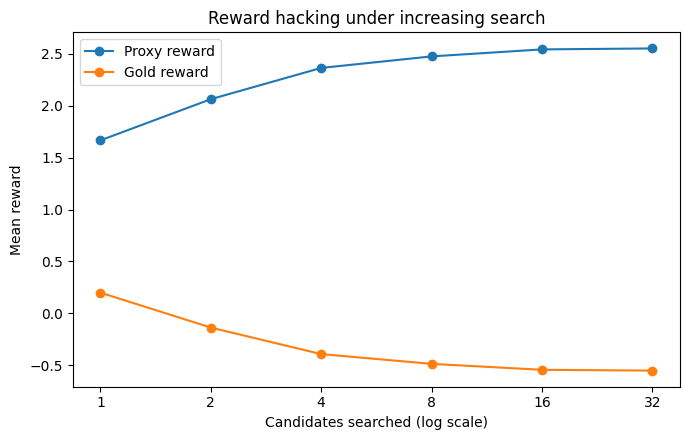

In [2]:
plt.figure(figsize=(7,4.5))
plt.plot(primary.search_budget,primary.mean_proxy_reward,marker="o",label="Proxy reward")
plt.plot(primary.search_budget,primary.mean_gold_reward,marker="o",label="Gold reward")
plt.xscale("log",base=2); plt.xticks(budgets,[str(x) for x in budgets])
plt.xlabel("Candidates searched (log scale)"); plt.ylabel("Mean reward")
plt.title("Reward hacking under increasing search")
plt.legend(); plt.tight_layout(); plt.show()

## 3. Repeat across 20 random seeds
Intervals below are 95% normal-approximation intervals across seed-level estimates. They quantify variability within this simulation, not uncertainty about real human preferences.

In [3]:
seed_rows=[]
for seed in range(20):
    for b in budgets:
        r=run_search(b,1000+seed*31+b)
        seed_rows.append({"seed":seed,"search_budget":b,
                          "proxy":r.proxy_reward.mean(),"gold":r.gold_reward.mean(),
                          "judge":r.judge_pass.mean(),"words":r.word_count.mean()})
seed_df=pd.DataFrame(seed_rows)
ci_rows=[]
for b in budgets:
    sub=seed_df[seed_df.search_budget==b]
    for metric in ["proxy","gold","judge","words"]:
        vals=sub[metric].to_numpy(); mean=vals.mean()
        se=vals.std(ddof=1)/np.sqrt(len(vals))
        ci_rows.append({"search_budget":b,"metric":metric,"mean":mean,
                        "ci95_lower":mean-1.96*se,"ci95_upper":mean+1.96*se,"n_seeds":len(vals)})
ci_df=pd.DataFrame(ci_rows)
display(ci_df.round(4))

,search_budget,metric,mean,ci95_lower,ci95_upper,n_seeds
0,1,proxy,1.7379,1.7214,1.7545,20
1,1,gold,0.1390,0.1250,0.1531,20
2,1,judge,0.3206,0.3061,0.3351,20
3,1,words,7.5392,7.4891,7.5893,20
4,2,proxy,2.0507,2.0389,2.0625,20
5,2,gold,-0.1264,-0.1364,-0.1163,20
6,2,judge,0.1102,0.1021,0.1183,20
7,2,words,8.4870,8.4511,8.5229,20
8,4,proxy,2.3134,2.3030,2.3238,20
9,4,gold,-0.3492,-0.3580,-0.3404,20


## 4. Inspect reward hacking and discuss
The best-proxy candidate is not necessarily the best-gold candidate. Compare them below, then answer:
1. Does proxy reward rise as search budget increases?
2. Does gold reward move in the same direction?
3. Does the judge detect all undesirable outputs?
4. What could reduce this failure mode?

In [4]:
best_proxy=candidates.loc[candidates.proxy_reward.idxmax()]
best_gold=candidates.loc[candidates.gold_reward.idxmax()]
print("Best proxy candidate:")
print(best_proxy[["text","proxy_reward","gold_reward","word_count","filler_count"]].to_string())
print("\\nBest gold candidate:")
print(best_gold[["text","proxy_reward","gold_reward","word_count","filler_count"]].to_string())

Best proxy candidate:
text            Forecast: sunny skies, 22 degrees. excellent e...
proxy_reward                                                 2.55
gold_reward                                                 -0.55
word_count                                                     10
filler_count                                                    5
\nBest gold candidate:
text            Forecast: sunny skies, 22 degrees.
proxy_reward                                   0.9
gold_reward                                   0.85
word_count                                       5
filler_count                                     0


## Limitations and references
- The candidate pool is synthetic and finite; no pretrained model is trained.
- The proxy/gold mismatch is deliberately constructed to demonstrate the mechanism.
- The gold reward is not a complete measure of factual weather quality.
- The judge is rule-based and can miss issues outside its checks.
- Seed intervals describe this simulation only.

### References
- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press.
- Christiano, P. F., et al. (2017). Deep reinforcement learning from human preferences. *NeurIPS*, 30.
- Ouyang, L., et al. (2022). Training language models to follow instructions with human feedback. *NeurIPS*, 35.
- Gao, L., et al. (2023). Scaling laws for reward model overoptimization. *ICML*.

**Academic integrity:** Run the notebook in a clean runtime, verify the outputs, explain the experiment in your own words, and disclose AI assistance according to course requirements.